establecer directorio de trabajo, forzar la raíz del proyecto

In [2]:
import os
print("Directorio actual:", os.getcwd())
print("¿Existe data/raw/hf_dataset?", os.path.exists("data/raw/hf_dataset"))
print("Contenido aquí:", os.listdir(".")[:10])

Directorio actual: /Users/marior/Documents/5to Semestre/DNN para vision computacional/proyectovision/notebooks
¿Existe data/raw/hf_dataset? False
Contenido aquí: ['01_eda.ipynb']


In [3]:
import os
from pathlib import Path

# Sube desde notebooks/ hasta la raíz del proyecto
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

os.chdir(PROJECT_ROOT)
print("Raíz del proyecto:", Path.cwd())
print("¿Existe data/raw/hf_dataset?", (PROJECT_ROOT / "data/raw/hf_dataset").exists())

Raíz del proyecto: /Users/marior/Documents/5to Semestre/DNN para vision computacional/proyectovision
¿Existe data/raw/hf_dataset? True


Celda 1 — imports y carga



In [4]:
from datasets import load_from_disk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ds = load_from_disk("data/raw/hf_dataset")["train"]
print(ds)
print("Columnas:", ds.column_names)
print("Ejemplo de metadata keys:", list(ds[0]["metadata"].keys()))

Dataset({
    features: ['images', 'metadata', 'results'],
    num_rows: 16880
})
Columnas: ['images', 'metadata', 'results']
Ejemplo de metadata keys: ['corners', 'tile_coords', 'tile_metadata', 'transformed_trees', 'trees']


Celda 2 — ¿cuántos árboles por tile?



In [5]:
n_trees = [len(ds[i]["metadata"]["transformed_trees"]) for i in range(len(ds))]
n_trees = np.array(n_trees)
print(f"Tiles: {len(n_trees)}")
print(f"Árboles totales: {n_trees.sum()}")
print(f"Árboles por tile -> min={n_trees.min()}, max={n_trees.max()}, media={n_trees.mean():.1f}, mediana={np.median(n_trees):.1f}")
print(f"Tiles con 0 árboles: {(n_trees == 0).sum()} ({100*(n_trees==0).mean():.2f}%)")

Tiles: 16880
Árboles totales: 1002429
Árboles por tile -> min=0, max=517, media=59.4, mediana=48.0
Tiles con 0 árboles: 1919 (11.37%)


Celda 3 — histograma de árboles por tile (para el datasheet)



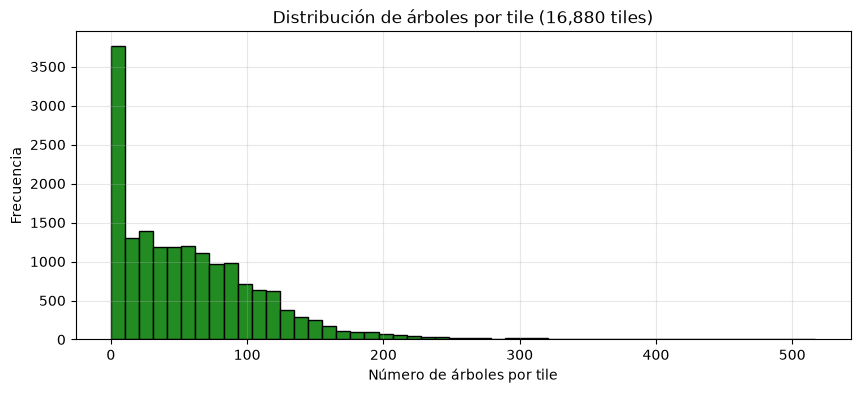

In [6]:
plt.figure(figsize=(10,4))
plt.hist(n_trees, bins=50, color="forestgreen", edgecolor="black")
plt.xlabel("Número de árboles por tile")
plt.ylabel("Frecuencia")
plt.title("Distribución de árboles por tile (16,880 tiles)")
plt.grid(alpha=0.3)
Path("docs/figuras").mkdir(parents=True, exist_ok=True)
plt.savefig("docs/figuras/eda_arboles_por_tile.png", dpi=120, bbox_inches="tight")
plt.show()

Celda 4 — distribución de radios (detección de outliers)



Radios -> min=18, max=102, media=32.52, mediana=31.00
Percentiles 1/5/50/95/99: [18. 19. 31. 49. 59.]


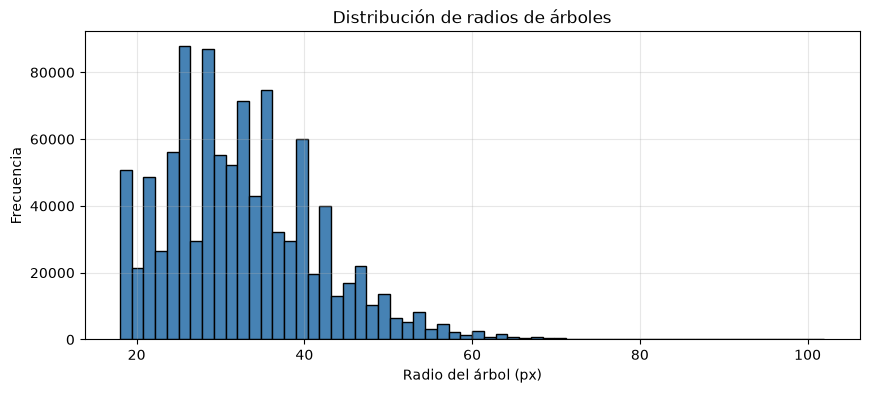

In [7]:
radii = []
for i in range(len(ds)):
    for t in ds[i]["metadata"]["transformed_trees"]:
        radii.append(t["radius"])
radii = np.array(radii)
print(f"Radios -> min={radii.min()}, max={radii.max()}, media={radii.mean():.2f}, mediana={np.median(radii):.2f}")
print(f"Percentiles 1/5/50/95/99: {np.percentile(radii,[1,5,50,95,99]).round(2)}")

plt.figure(figsize=(10,4))
plt.hist(radii, bins=60, color="steelblue", edgecolor="black")
plt.xlabel("Radio del árbol (px)")
plt.ylabel("Frecuencia")
plt.title("Distribución de radios de árboles")
plt.grid(alpha=0.3)
plt.savefig("docs/figuras/eda_radios.png", dpi=120, bbox_inches="tight")
plt.show()

Celda 5 — visualiza 3 tiles con sus anotaciones (para verificar etiquetas)



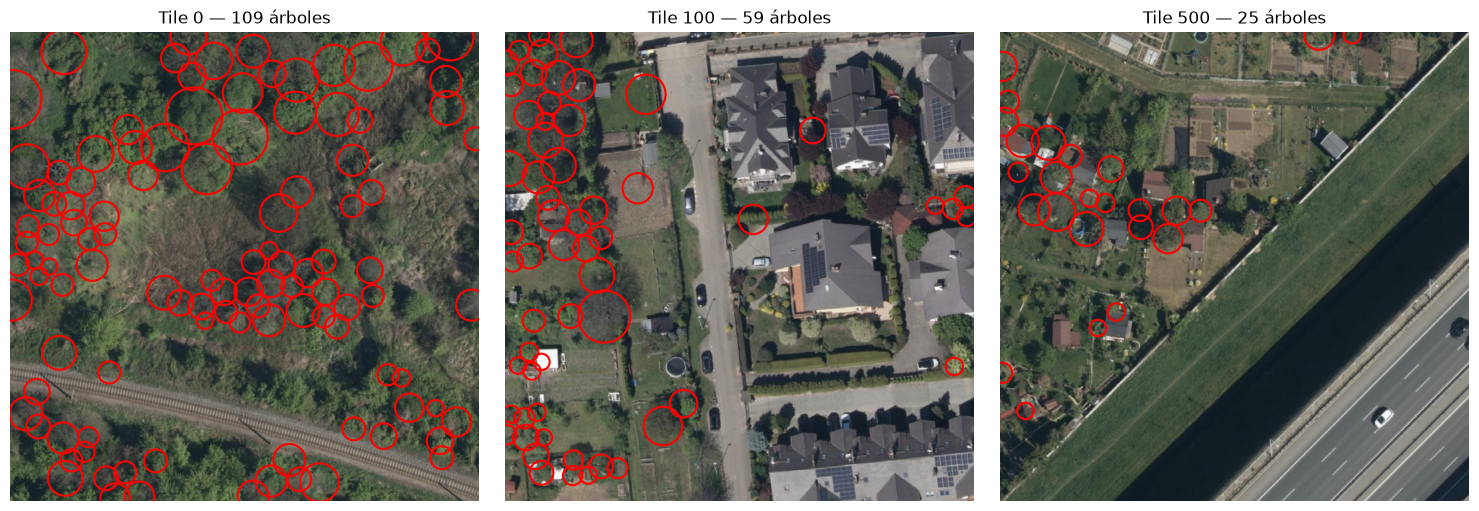

In [8]:
import matplotlib.patches as patches

fig, axes = plt.subplots(1, 3, figsize=(15,5))
idxs = [0, 100, 500]
for ax, i in zip(axes, idxs):
    img = ds[i]["images"].convert("RGB")
    ax.imshow(img)
    for t in ds[i]["metadata"]["transformed_trees"]:
        circ = patches.Circle((t["x"], t["y"]), t["radius"], fill=False, color="red", lw=1.5)
        ax.add_patch(circ)
    ax.set_title(f"Tile {i} — {len(ds[i]['metadata']['transformed_trees'])} árboles")
    ax.axis("off")
plt.tight_layout()
plt.savefig("docs/figuras/eda_ejemplos_anotados.png", dpi=120, bbox_inches="tight")
plt.show()

Celda 6 — guarda un resumen en CSV para el datasheet



In [9]:
df = pd.DataFrame({"tile_idx": range(len(ds)), "n_trees": n_trees})
df.to_csv("docs/figuras/eda_resumen_tiles.csv", index=False)
print(df.describe())
print("Guardado en docs/figuras/eda_resumen_tiles.csv")

           tile_idx       n_trees
count  16880.000000  16880.000000
mean    8439.500000     59.385604
std     4872.980607     56.995488
min        0.000000      0.000000
25%     4219.750000     14.000000
50%     8439.500000     48.000000
75%    12659.250000     88.000000
max    16879.000000    517.000000
Guardado en docs/figuras/eda_resumen_tiles.csv


Anotación para la defensa (guárdala)
"El dataset solo trae split train (16,880 tiles). Por eso nosotros construimos train/val/test a nivel de tile, no de árbol, para evitar fuga de información: árboles del mismo tile comparten contexto visual. Esto lo justificamos en B3."

Eso es exactamente el tipo de decisión que E2 premia.

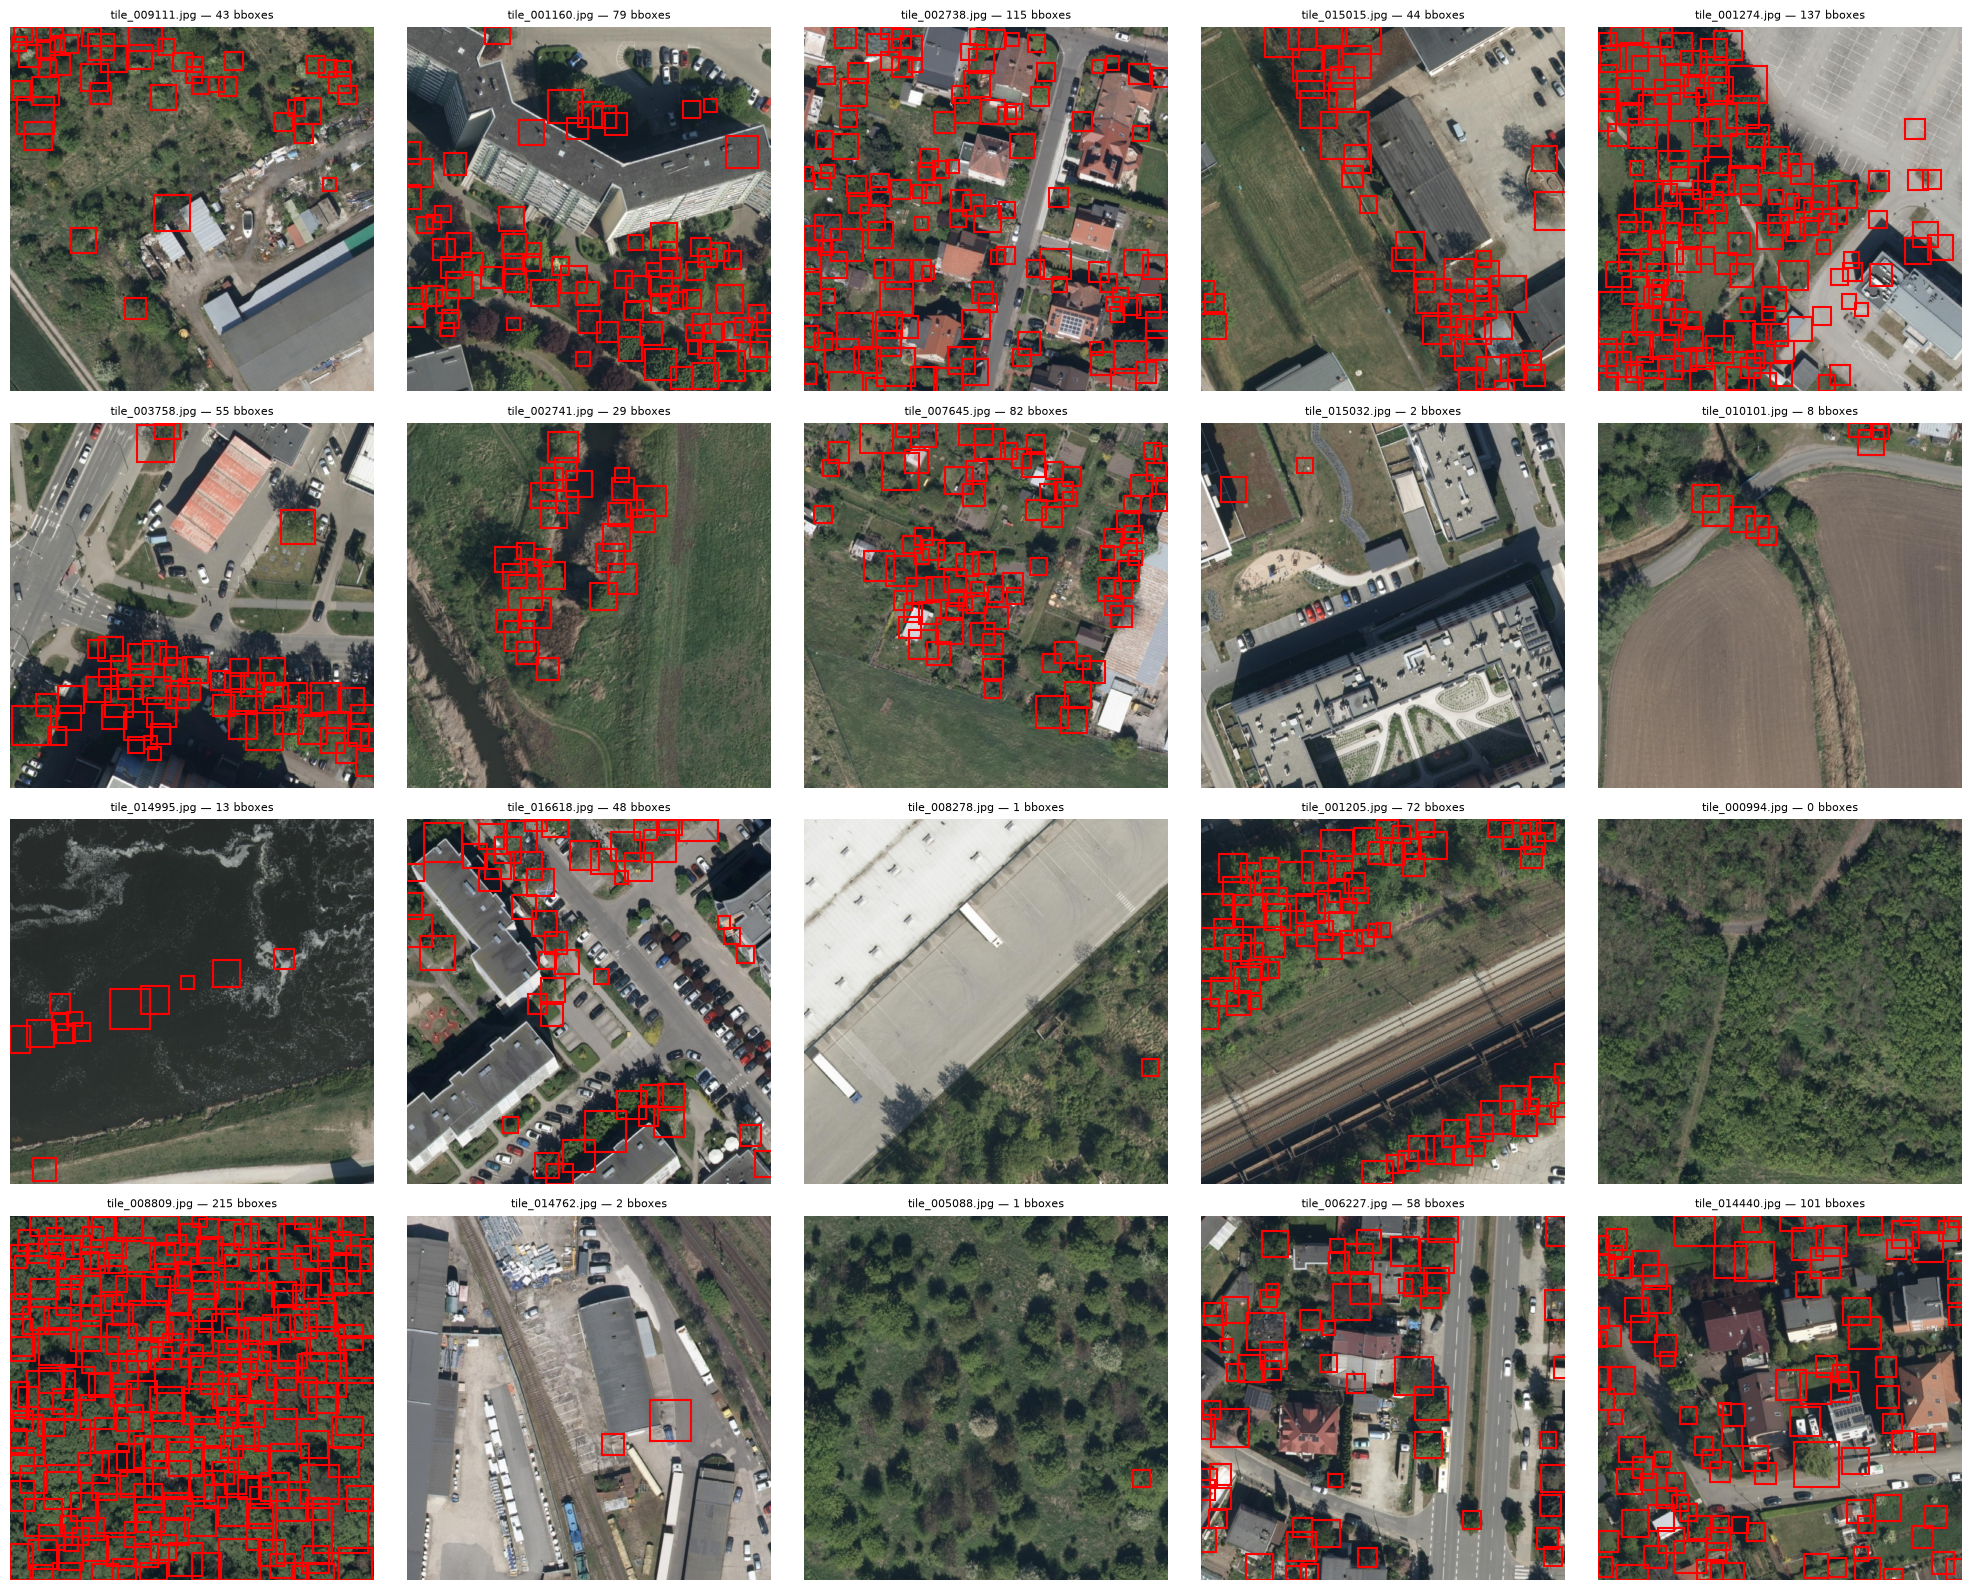

In [10]:
import random, matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
from pathlib import Path

IMG_DIR = Path("data/processed/images/train")
LBL_DIR = Path("data/processed/labels/train")
files = random.sample(sorted(IMG_DIR.glob("*.jpg")), 20)

fig, axes = plt.subplots(4,5, figsize=(20,16))
for ax, f in zip(axes.ravel(), files):
    img = Image.open(f); W,H = img.size
    ax.imshow(img)
    lbl = (LBL_DIR / (f.stem + ".txt")).read_text().strip().splitlines()
    for line in lbl:
        _, xc,yc,w,h = map(float, line.split())
        x1=(xc-w/2)*W; y1=(yc-h/2)*H
        ax.add_patch(patches.Rectangle((x1,y1), w*W, h*H, fill=False, color="red", lw=1.5))
    ax.set_title(f"{f.name} — {len(lbl)} bboxes", fontsize=8); ax.axis("off")
plt.tight_layout()
plt.savefig("docs/figuras/revision_20_muestras.png", dpi=110, bbox_inches="tight")
plt.show()